<a href="https://colab.research.google.com/github/kangtayie/Machine-Learning_class/blob/main/abalone_classification_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. 데이터 불러오기
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/abalone.csv')
df.head()

,id,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
0,0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [17]:
# 2. 데이터 확인
print(df.shape)
print(df["Sex"].value_counts())
df.describe()

(4177, 10)
Sex
M    1528
I    1342
F    1307
Name: count, dtype: int64


,id,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
count,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000
mean,2088.000000,0.523992,0.407881,0.139516,0.828742,0.359367,0.180594,0.238831,9.933684
std,1205.940366,0.120093,0.099240,0.041827,0.490389,0.221963,0.109614,0.139203,3.224169
min,0.000000,0.075000,0.055000,0.000000,0.002000,0.001000,0.000500,0.001500,1.000000
25%,1044.000000,0.450000,0.350000,0.115000,0.441500,0.186000,0.093500,0.130000,8.000000
50%,2088.000000,0.545000,0.425000,0.140000,0.799500,0.336000,0.171000,0.234000,9.000000
75%,3132.000000,0.615000,0.480000,0.165000,1.153000,0.502000,0.253000,0.329000,11.000000
max,4176.000000,0.815000,0.650000,1.130000,2.825500,1.488000,0.760000,1.005000,29.000000


In [18]:
# 3. 이상치 확인 및 제거
print("Height가 0인 행:", (df["Height"] == 0).sum())                                   # 높이 0은 불가능
print("살 무게 > 전체 무게인 행:", (df["Shucked_weight"] > df["Whole_weight"]).sum())  # 부분이 전체보다 무거울 수 없음

df = df[df["Height"] > 0]
df = df[df["Shucked_weight"] <= df["Whole_weight"]]
df = df.drop("id", axis=1)                                                             # id는 단순 번호라 예측에 쓸모없음
print(df.shape)

Height가 0인 행: 2
살 무게 > 전체 무게인 행: 4
(4171, 9)


In [19]:
# 4. Sex(성별) 컬럼 원-핫 인코딩
# M/F/I는 크기 순서가 없는 범주라 0/1/2로 바꾸면 "I > F" 같은 잘못된 순서가 생김
# → Sex_F, Sex_I, Sex_M 3개 컬럼(0/1)으로 나눔
df = pd.get_dummies(df, columns=["Sex"], dtype=int)
df.head()

,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings,Sex_F,Sex_I,Sex_M
0,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15,0,0,1
1,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7,0,0,1
2,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9,1,0,0
3,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10,0,0,1
4,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7,0,1,0


In [20]:
# 5. 레이블(Rings) 분포 확인
print(df["Rings"].value_counts().sort_index())
# Rings가 1~29까지 28종류인데, 1·2·25 이상은 1~2개뿐이라 그대로 분류하면 거의 못 맞힘
# → 개수가 비슷하도록 3그룹으로 묶음: 0 = 어림(1~8), 1 = 성체(9~10), 2 = 늙음(11 이상)

Rings
1       1
2       1
3      15
4      57
5     113
6     258
7     389
8     567
9     689
10    634
11    487
12    267
13    203
14    126
15    103
16     67
17     58
18     42
19     32
20     26
21     14
22      6
23      9
24      2
25      1
26      1
27      2
29      1
Name: count, dtype: int64


In [21]:
# 6. Rings → 3개 클래스로 변환
df["Age_group"] = pd.cut(df["Rings"], bins=[0, 8, 10, 30], labels=[0, 1, 2]).astype(int)
print(df["Age_group"].value_counts().sort_index())   # 세 그룹이 1300~1400개로 고르게 나뉨

Age_group
0    1401
1    1323
2    1447
Name: count, dtype: int64


In [22]:
# 7. 입력 / 정답 분리
X = df.drop(["Rings", "Age_group"], axis=1).values   # 입력: 측정값 7개 + Sex 원-핫 3개 = 10개
y = df["Age_group"].values                           # 정답: 나이 그룹 (0/1/2)

# 8. 학습 / 테스트 데이터 분리
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 9. 데이터 정규화
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 10. 정답 원-핫 인코딩
# 클래스가 3개 이상이면 softmax 출력(3칸)과 모양을 맞추기 위해 정답도 [1,0,0] 형태로 바꿈
y_train_oh = tf.keras.utils.to_categorical(y_train, num_classes=3)
y_test_oh = tf.keras.utils.to_categorical(y_test, num_classes=3)
print(y_train[:3], "→", y_train_oh[:3])

[1 1 0] → [[0. 1. 0.]
 [0. 1. 0.]
 [1. 0. 0.]]


In [23]:
# 11. 모델 생성
model = tf.keras.Sequential()
model.add(tf.keras.layers.Input(shape=(10,)))
model.add(tf.keras.layers.Dense(32, activation="relu"))
model.add(tf.keras.layers.Dense(16, activation="relu"))
model.add(tf.keras.layers.Dense(3, activation="softmax"))   # 다중 분류: 3개 클래스 확률 (합 = 1)

# 12. 모델 설정
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

In [24]:
# 13. 모델 구조 출력
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 931 (3.64 KB)

 Trainable params: 931 (3.64 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
# 14. 모델 학습
history = model.fit(X_train, y_train_oh, epochs=50, batch_size=32, validation_split=0.2, verbose=1)

Epoch 1/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.5225 - loss: 0.9529 - val_accuracy: 0.6587 - val_loss: 0.7816
Epoch 2/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5952 - loss: 0.8258 - val_accuracy: 0.6662 - val_loss: 0.7310
Epoch 3/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6109 - loss: 0.8002 - val_accuracy: 0.6841 - val_loss: 0.7138
Epoch 4/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6278 - loss: 0.7836 - val_accuracy: 0.6841 - val_loss: 0.6928
Epoch 5/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.6364 - loss: 0.7700 - val_accuracy: 0.6737 - val_loss: 0.6963
Epoch 6/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6454 - loss: 0.7570 - val_accuracy: 0.6946 - val_loss: 0.6775
Epoch 7/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6466 - loss: 0.7489 - val_accuracy: 0.6826 - val_loss: 0.6815
Epoch 8/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6529 - loss: 0.7433 - val_accuracy: 0.6991 - val_los

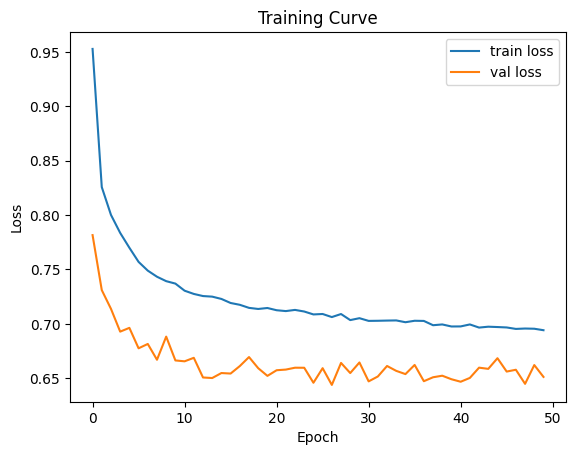

In [26]:
# 15. 학습 곡선 시각화
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Training Curve")
plt.show()

In [27]:
# 16. 테스트 데이터 예측
y_prob = model.predict(X_test)             # 각 클래스 확률 3개
y_pred = np.argmax(y_prob, axis=1)         # 확률이 가장 큰 칸의 번호 = 예측 클래스

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [28]:
# 17. 성능 평가
print("Accuracy =", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=["young(1~8)", "adult(9~10)", "old(11+)"]))

Accuracy = 0.6263473053892216
[[200  66  14]
 [ 55 147  63]
 [ 16  98 176]]
              precision    recall  f1-score   support

  young(1~8)       0.74      0.71      0.73       280
 adult(9~10)       0.47      0.55      0.51       265
    old(11+)       0.70      0.61      0.65       290

    accuracy                           0.63       835
   macro avg       0.64      0.63      0.63       835
weighted avg       0.64      0.63      0.63       835

